In [3]:
# ✅ Step 1: Install & Import Required Libraries
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import MobileNetV2  # Updated from ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing import image


In [13]:
import os
import shutil
import random

# ✅ Define source and destination paths
raw_train_dir = "./dataset/train"
raw_test_dir = "./dataset/test"
balanced_train_dir = "./dataset/balanced/train"
balanced_test_dir = "./dataset/balanced/test"

# ✅ Ensure balanced dataset directories exist
for folder in [balanced_train_dir, balanced_test_dir]:
    os.makedirs(folder, exist_ok=True)

# ✅ Function to balance dataset from separate train & test sets
def balance_dataset(train_src, test_src, train_dest, test_dest, train_size=1400, test_size=380):
    for class_name in os.listdir(train_src):  # Iterate through each class
        train_class_path = os.path.join(train_src, class_name)
        test_class_path = os.path.join(test_src, class_name)

        # Ensure class exists in both train & test folders
        if not os.path.exists(test_class_path):
            print(f" Warning: Test folder missing for class {class_name}, skipping...")
            continue

        # Get all images in the class
        train_images = os.listdir(train_class_path)
        test_images = os.listdir(test_class_path)

        # Ensure enough images exist for both train & test
        if len(train_images) < train_size:
            print(f" Warning: Not enough train images in {class_name} (Found: {len(train_images)}, Needed: {train_size})")
            continue

        if len(test_images) < test_size:
            print(f" Warning: Not enough test images in {class_name} (Found: {len(test_images)}, Needed: {test_size})")
            continue

        # Shuffle and select images
        random.shuffle(train_images)
        random.shuffle(test_images)
        selected_train = train_images[:train_size]  # Take 1400 for training
        selected_test = test_images[:test_size]  # Take 380 for testing

        # Create class directories in balanced dataset
        os.makedirs(os.path.join(train_dest, class_name), exist_ok=True)
        os.makedirs(os.path.join(test_dest, class_name), exist_ok=True)

        # Copy selected images to the new balanced dataset
        for img in selected_train:
            shutil.copy(os.path.join(train_class_path, img), os.path.join(train_dest, class_name, img))

        for img in selected_test:
            shutil.copy(os.path.join(test_class_path, img), os.path.join(test_dest, class_name, img))

        print(f"✅ {class_name}: {train_size} train, {test_size} test images copied.")

# ✅ Run the balancing function
balance_dataset(raw_train_dir, raw_test_dir, balanced_train_dir, balanced_test_dir)

print("\n Dataset successfully balanced with 1400 train & 380 test images per class!")

✅ freshapples: 1400 train, 380 test images copied.
✅ freshbanana: 1400 train, 380 test images copied.
✅ freshoranges: 1400 train, 380 test images copied.
✅ rottenapples: 1400 train, 380 test images copied.
✅ rottenbanana: 1400 train, 380 test images copied.
✅ rottenoranges: 1400 train, 380 test images copied.

 Dataset successfully balanced with 1400 train & 380 test images per class!


In [14]:
# ✅ Update paths
train_dir = "./dataset/balanced/train"
test_dir = "./dataset/balanced/test"

In [15]:
import os

# ✅ Function to count images in each class
def count_images(folder):
    class_counts = {}
    for class_name in os.listdir(folder):
        class_path = os.path.join(folder, class_name)
        if os.path.isdir(class_path):
            class_counts[class_name] = len(os.listdir(class_path))
    return class_counts

# ✅ Check counts for training & testing datasets
train_counts = count_images("./dataset/balanced/train")
test_counts = count_images("./dataset/balanced/test")

# ✅ Print results
print("\n🔹 Training Data Count per Class:")
for class_name, count in train_counts.items():
    print(f"{class_name}: {count} images")

print("\n🔹 Testing Data Count per Class:")
for class_name, count in test_counts.items():
    print(f"{class_name}: {count} images")


🔹 Training Data Count per Class:
freshapples: 1400 images
freshbanana: 1400 images
freshoranges: 1400 images
rottenapples: 1400 images
rottenbanana: 1400 images
rottenoranges: 1400 images

🔹 Testing Data Count per Class:
freshapples: 380 images
freshbanana: 380 images
freshoranges: 380 images
rottenapples: 380 images
rottenbanana: 380 images
rottenoranges: 380 images


In [16]:
# ✅ Step 3: Data Augmentation & Normalization
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,  # 20% for validation
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)


In [17]:
# ✅ Step 4: Load Data Using Data Generators
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 6720 images belonging to 6 classes.
Found 1680 images belonging to 6 classes.
Found 2280 images belonging to 6 classes.


In [18]:
# ✅ Step 5: Load Pretrained MobileNetV2 Model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the first 100 layers to retain pretrained features
for layer in base_model.layers[:100]:
    layer.trainable = False


In [19]:
# ✅ Step 6: Build Custom Classification Layers
inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.2)(x)
outputs = Dense(len(train_generator.class_indices), activation='softmax')(x)

# Define the Model
model = Model(inputs, outputs)


In [20]:

# ✅ Step 7: Compile Model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])


In [21]:
# ✅ Step 8: Add Early Stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)


In [22]:
# ✅ Step 9: Train Model
history = model.fit(train_generator, validation_data=val_generator, epochs=20, callbacks=[early_stopping])

Epoch 1/20
210/210 ━━━━━━━━━━━━━━━━━━━━ 595s 3s/step - accuracy: 0.7944 - loss: 0.5778 - val_accuracy: 0.6202 - val_loss: 1.5052
Epoch 2/20
210/210 ━━━━━━━━━━━━━━━━━━━━ 357s 2s/step - accuracy: 0.9747 - loss: 0.0673 - val_accuracy: 0.7530 - val_loss: 1.0004
Epoch 3/20
210/210 ━━━━━━━━━━━━━━━━━━━━ 298s 1s/step - accuracy: 0.9884 - loss: 0.0330 - val_accuracy: 0.7304 - val_loss: 1.1724
Epoch 4/20
210/210 ━━━━━━━━━━━━━━━━━━━━ 276s 1s/step - accuracy: 0.9906 - loss: 0.0258 - val_accuracy: 0.8315 - val_loss: 0.6185
Epoch 5/20
210/210 ━━━━━━━━━━━━━━━━━━━━ 269s 1s/step - accuracy: 0.9890 - loss: 0.0342 - val_accuracy: 0.9827 - val_loss: 0.0449
Epoch 6/20
210/210 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.9927 - loss: 0.0220 - val_accuracy: 0.9863 - val_loss: 0.0396
Epoch 7/20
210/210 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.9962 - loss: 0.0130 - val_accuracy: 0.9821 - val_loss: 0.0546
Epoch 8/20
210/210 ━━━━━━━━━━━━━━━━━━━━ 228s 1s/step - accuracy: 0.9967 - loss: 0.0101 - val_accu

In [28]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


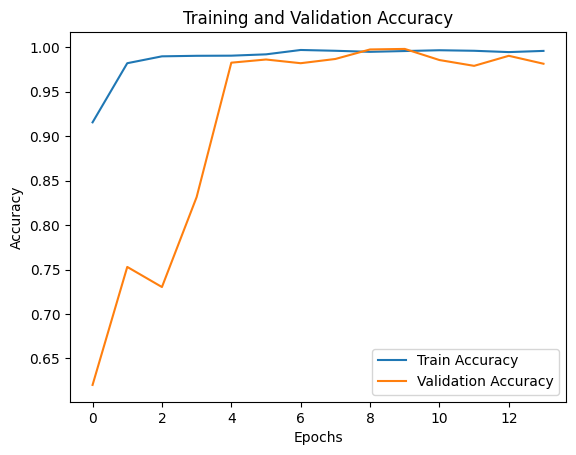

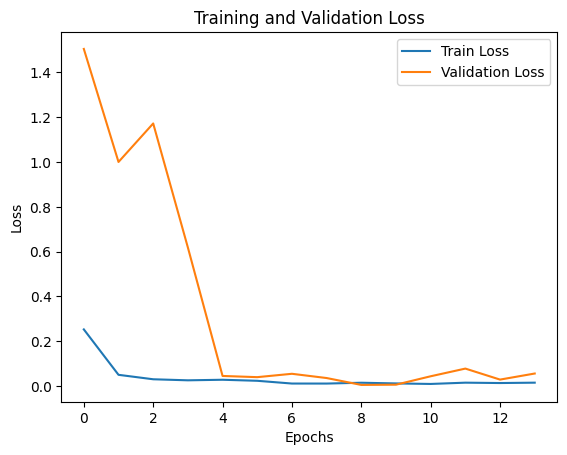

In [29]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()

# Plot training & validation loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

In [30]:
final_train_acc = history.history['accuracy'][-1] * 100
final_val_acc = history.history['val_accuracy'][-1] * 100

print(f"Final Training Accuracy: {final_train_acc:.2f}%")
print(f"Final Validation Accuracy: {final_val_acc:.2f}%")

Final Training Accuracy: 99.60%
Final Validation Accuracy: 98.15%


In [23]:
model.save("model_mobile.h5")

In [33]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
import random
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load the saved model
model = load_model("model_mobile.h5")

# Define test data generator
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)  # MobileNetV2 preprocessing

test_generator = test_datagen.flow_from_directory(
    "./dataset/test",  # Replace with actual test set path
    target_size=(224, 224),  # MobileNetV2 input size
    batch_size=1,
    class_mode="categorical",
    shuffle=False
)

# Get class labels
class_labels = list(test_generator.class_indices.keys())

# Load test images and labels
X_test, y_test = [], []
num_classes = len(class_labels)
samples_per_class = 10  # Number of images per class

# Collect 10 images from each class
for class_idx in range(num_classes):
    class_images = []
    for i in range(len(test_generator.filenames)):
        if test_generator.classes[i] == class_idx:
            img, label = test_generator[i]
            class_images.append((img[0], label[0]))  # Store image and label
            if len(class_images) >= samples_per_class:
                break
    X_test.extend(class_images)

# Shuffle collected images
random.shuffle(X_test)

# Extract images and labels
images, true_labels = zip(*X_test)
images = np.array(images)
true_labels = np.argmax(np.array(true_labels), axis=1)  # Convert one-hot to class index

Found 2698 images belonging to 6 classes.


1/2 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000248378E4B80> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step


ValueError: num must be an integer with 1 <= num <= 20, not 21

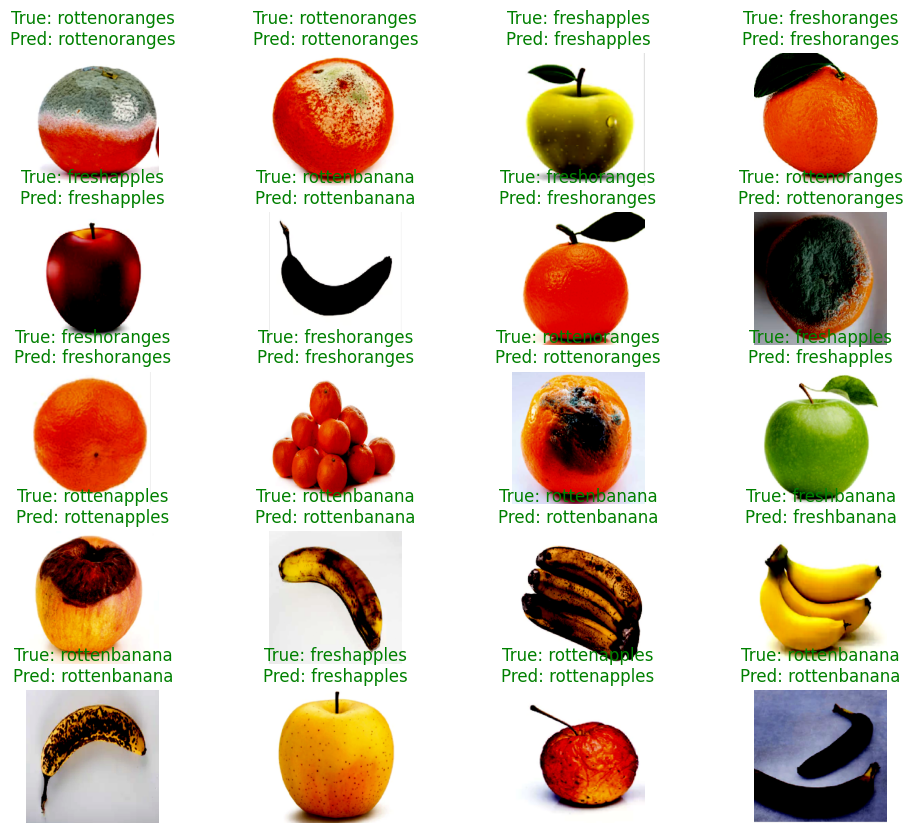

In [34]:
# Get predictions
preds = model.predict(images)
pred_labels = np.argmax(preds, axis=1)

# Plot images with predictions
plt.figure(figsize=(12, 10))
for i in range(len(images)):
    plt.subplot(5, 4, i + 1)  # Adjust rows/cols as needed
    plt.imshow(images[i])
    true_class = class_labels[true_labels[i]]
    pred_class = class_labels[pred_labels[i]]
    color = "green" if true_class == pred_class else "red"
    plt.title(f"True: {true_class}\nPred: {pred_class}", color=color)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image

# Load the model
model_path = "model_mobile.h5"
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Model file '{model_path}' not found!")

model = tf.keras.models.load_model(model_path)

# Define class labels
class_labels = ['freshapples', 'freshbanana', 'freshoranges', 
                'rottenapples', 'rottenbanana', 'rottenoranges']

# Load and preprocess image
img_path = "./dataset/fresh orange.jpeg.jpg"
if not os.path.exists(img_path):
    raise FileNotFoundError(f"Image file '{img_path}' not found!")

img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0  # Normalize

# Predict
predictions = model.predict(img_array)
predicted_class = np.argmax(predictions)
predicted_class_name = class_labels[predicted_class]

print(f"Predicted class: {predicted_class_name}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted class: freshoranges


In [4]:
# import numpy as np
# import tensorflow as tf
# from tensorflow.keras.models import Model
# from tensorflow.keras.applications import MobileNetV2
# from tensorflow.keras.layers import GlobalAveragePooling2D
# from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# # Load pre-trained MobileNetV2 without the classification head
# base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# # Manually apply Global Average Pooling to extract feature vectors
# x = base_model.output
# x = GlobalAveragePooling2D()(x)  # Apply GAP to reduce spatial dimensions
# feature_extractor = Model(inputs=base_model.input, outputs=x)

# # Function to extract features
# def extract_features(images):
#     """Extract deep features from images using MobileNetV2."""
#     images = np.array(images) / 255.0  # Normalize images
#     images = preprocess_input(images)  # MobileNetV2 preprocessing
#     features = feature_extractor.predict(images)
#     return features  # Shape: (num_samples, 1280)


import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D

# Load pre-trained MobileNetV2 without the top layer
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Add a GlobalAveragePooling2D layer manually
x = GlobalAveragePooling2D()(base_model.output)

# Create new model for feature extraction
feature_extractor = Model(inputs=base_model.input, outputs=x)


In [5]:
import cv2
import numpy as np
import os
from glob import glob

# Path to your dataset folder
dataset_path = "./dataset"

# Get all image file paths
image_paths = glob(os.path.join(dataset_path, "*.jpg"))  # Adjust extension if needed

# Load and preprocess images
images = []
for img_path in image_paths:
    img = cv2.imread(img_path)  # Load image
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
        img = cv2.resize(img, (224, 224))  # Resize to MobileNetV2 input size
        images.append(img)

# Convert list to NumPy array
resized_images = np.array(images, dtype=np.float32) / 255.0  # Normalize

print("Loaded images shape:", resized_images.shape)  # Should be (num_samples, 224, 224, 3)


Loaded images shape: (4, 224, 224, 3)


In [6]:
print("Resized Images Shape:", resized_images.shape)
print("Data Type:", type(resized_images))


Resized Images Shape: (4, 224, 224, 3)
Data Type: <class 'numpy.ndarray'>


In [7]:
# Get the minimum of num_samples and num_features
num_samples, num_features = deep_features.shape
n_components = min(300, num_samples)  # Ensure PCA does not exceed sample size

# Apply PCA
pca = PCA(n_components=n_components)
pca_features = pca.fit_transform(deep_features)

print("Original feature shape:", deep_features.shape)
print("Reduced feature shape:", pca_features.shape)


NameError: name 'deep_features' is not defined

In [7]:
import os
import numpy as np
import cv2
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder

def load_images_with_labels(directory):
    images = []
    labels = []
    class_names = sorted(os.listdir(directory))  # Get class names

    for class_name in class_names:
        class_dir = os.path.join(directory, class_name)
        if not os.path.isdir(class_dir):  # Skip non-directory files
            continue

        print(f"📂 Loading '{class_name}' images...")
        
        for filename in tqdm(os.listdir(class_dir)):
            img_path = os.path.join(class_dir, filename)
            img = cv2.imread(img_path)
            if img is None:
                print(f"⚠️ Skipping '{filename}' (not an image)")
                continue
            
            img = cv2.resize(img, (224, 224))  # Resize to match MobileNetV2 input size
            img = img / 255.0  # Normalize pixel values
            images.append(img)
            labels.append(class_name)  # Use folder name as label

    if len(images) == 0:
        print(f"❌ Error: No images found in '{directory}'!")
        return np.array([]), np.array([])

    return np.array(images), np.array(labels)

# Paths to dataset
train_dir = "dataset/train/"
test_dir = "dataset/test/"

# Load images and labels
train_images, train_labels = load_images_with_labels(train_dir)
test_images, test_labels = load_images_with_labels(test_dir)

# Encode text labels into numerical values
label_encoder = LabelEncoder()
train_labels = label_encoder.fit_transform(train_labels)
test_labels = label_encoder.transform(test_labels)

print("✅ Train Images Shape:", train_images.shape)
print("✅ Train Labels Shape:", train_labels.shape)
print("✅ Test Images Shape:", test_images.shape)
print("✅ Test Labels Shape:", test_labels.shape)
print("🔢 Classes:", label_encoder.classes_)  # Shows class names


📂 Loading 'freshapples' images...


100%|██████████| 1693/1693 [00:06<00:00, 252.66it/s]


📂 Loading 'freshbanana' images...


100%|██████████| 1581/1581 [00:10<00:00, 147.91it/s]


📂 Loading 'freshoranges' images...


100%|██████████| 1466/1466 [00:07<00:00, 207.83it/s]


... (15 outputs left out)

100%|██████████| 530/530 [00:02<00:00, 209.57it/s]


📂 Loading 'rottenoranges' images...


100%|██████████| 403/403 [00:01<00:00, 212.51it/s]


✅ Train Images Shape: (10901, 224, 224, 3)
✅ Train Labels Shape: (10901,)
✅ Test Images Shape: (2698, 224, 224, 3)
✅ Test Labels Shape: (2698,)
🔢 Classes: ['freshapples' 'freshbanana' 'freshoranges' 'rottenapples' 'rottenbanana'
 'rottenoranges']


In [8]:
# Import PCA
from sklearn.decomposition import PCA

# Extract deep features using MobileNetV2
deep_features = feature_extractor.predict(train_images)

# Apply PCA (Ensure n_components is valid)
pca = PCA(n_components=min(300, deep_features.shape[0]))
pca_features = pca.fit_transform(deep_features)

print("📏 Original feature shape:", deep_features.shape)
print("📉 Reduced feature shape:", pca_features.shape)


341/341 ━━━━━━━━━━━━━━━━━━━━ 127s 368ms/step
📏 Original feature shape: (10901, 1280)
📉 Reduced feature shape: (10901, 300)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


# Extract deep features for test images
test_features = feature_extractor.predict(test_images)

# Apply the same PCA transformation on test_features
test_pca_features = pca.transform(test_features)  # Use transform, not fit_transform

X_train, X_test = pca_features, test_pca_features  # Use transformed test features
y_train, y_test = train_labels, test_labels

# Train a classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)

# Accuracy
print("🎯 Model Accuracy:", accuracy_score(y_test, y_pred))


85/85 ━━━━━━━━━━━━━━━━━━━━ 37s 435ms/step
🎯 Model Accuracy: 0.9899925871015567


In [10]:
train_features = feature_extractor.predict(train_images)
test_features = feature_extractor.predict(test_images)


341/341 ━━━━━━━━━━━━━━━━━━━━ 136s 398ms/step
85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 393ms/step


In [11]:
from sklearn.decomposition import PCA
from sklearn.svm import SVC
# from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1️⃣ Apply PCA to Train and Test Sets
pca = PCA(n_components=300)
X_train = pca.fit_transform(train_features)  # Fit PCA on train data
X_test = pca.transform(test_features)       # Transform test data

# Labels (Ensure labels are correct)
y_train, y_test = train_labels, test_labels

# 2️⃣ Train Models
models = {
    "SVM": SVC(kernel='rbf', C=1.0, gamma='scale'),
    # "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss'),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

# 3️⃣ Evaluate Models
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy:.4f}")


SVM Accuracy: 0.9952
Random Forest Accuracy: 0.9718
KNN Accuracy: 0.9896


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\arsha\Desktop\Fresh_Rotten_Class\venv\Scripts\python.exe -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\arsha\Desktop\Fresh_Rotten_Class\venv\Scripts\python.exe -m pip install --upgrade pip' command.


SVM Accuracy: 0.9952


PermutationExplainer explainer: 11it [11:30, 69.01s/it]                        
C:\Users\arsha\AppData\Local\Temp\ipykernel_16336\2443734870.py:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test[:10])  # Visualize feature importance


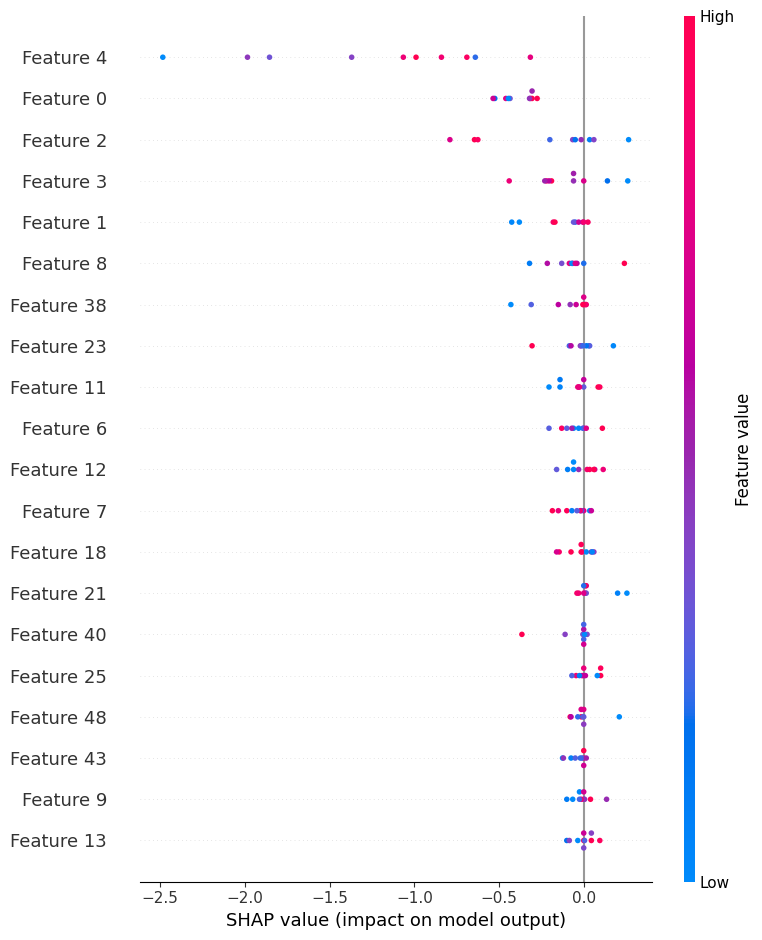

Random Forest Accuracy: 0.9722


PermutationExplainer explainer: 11it [00:11,  5.89s/it]               
C:\Users\arsha\AppData\Local\Temp\ipykernel_16336\2443734870.py:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test[:10])  # Visualize feature importance


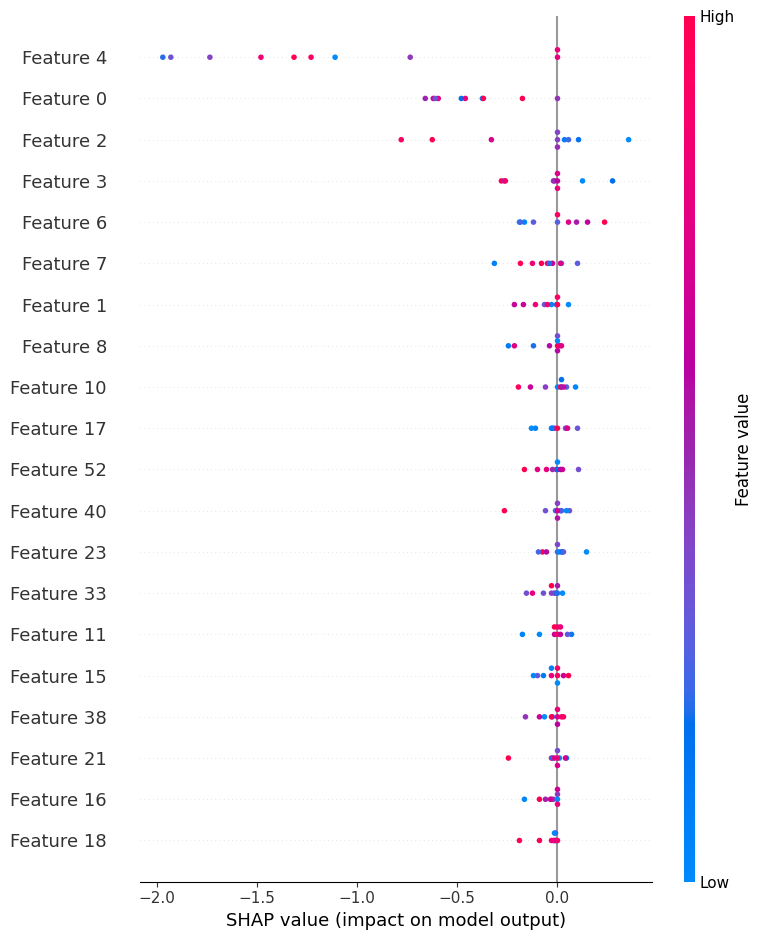

KNN Accuracy: 0.9889


PermutationExplainer explainer: 11it [02:56, 17.63s/it]                        
C:\Users\arsha\AppData\Local\Temp\ipykernel_16336\2443734870.py:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test[:10])  # Visualize feature importance


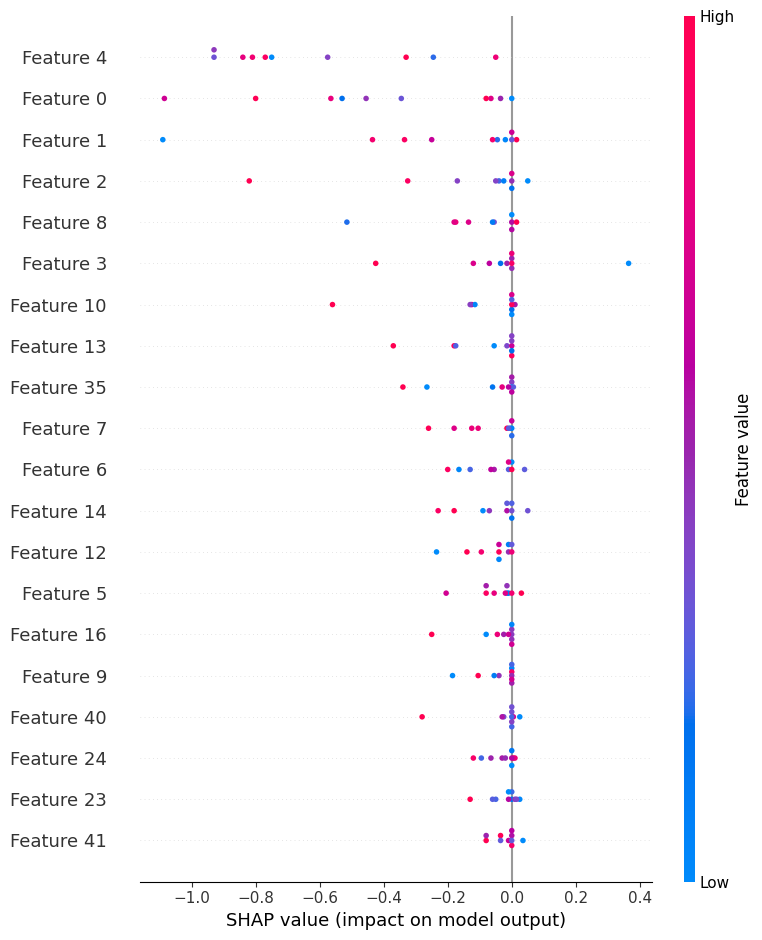

In [13]:
%pip install lime
%pip install shap


import shap
import lime.lime_tabular
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1️⃣ Apply PCA to Train and Test Sets
pca = PCA(n_components=300)
X_train = pca.fit_transform(train_features)  # Fit PCA on train data
X_test = pca.transform(test_features)       # Transform test data

# Labels (Ensure labels are correct)
y_train, y_test = train_labels, test_labels

# 2️⃣ Train Models
models = {
    "SVM": SVC(kernel='rbf', C=1.0, gamma='scale', probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

# 3️⃣ Evaluate Models & Apply XAI
explainers = {}  # Dictionary to store explainers

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy:.4f}")

    # 4️⃣ Apply SHAP (Feature Importance)
    explainer = shap.Explainer(model.predict, X_train)
    shap_values = explainer(X_test[:10], max_evals=601)  # Increase max_evals
    shap.summary_plot(shap_values, X_test[:10])  # Visualize feature importance

    

    # 5️⃣ Apply LIME (Local Explanation)
    lime_explainer = lime.lime_tabular.LimeTabularExplainer(
        X_train, feature_names=[f"PC{i+1}" for i in range(X_train.shape[1])], class_names=["Fresh", "Rotten"],
        mode="classification"
    )
    
    # Explain first test instance
    idx = 0
    lime_exp = lime_explainer.explain_instance(X_test[idx], model.predict_proba)
    lime_exp.show_in_notebook()

